# Lab 3: Working with Climate Data
Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel$\rightarrow$Restart) and then **run all cells** (in the menubar, select Cell$\rightarrow$Run All).

Add as many comments as you could when you solve the problem, which can help your remember what you have done.


***Submission***: For Python people, submit this Jupyter Notebook only

Name = "Noah Runions"

***Note:*** The functions/code provided are one of many ways that can work. Feel free to use functions you are more familiar with!\
***Figures:*** For any figures, label axis and title clearly for full points. 

## Lab Objectives:

1.	Understand Drought indicators: Identify and describe the differences between various drought indices such as CMI, PDSI, and SPI.
2.	Calculate and interpret mean, median, mode, and standard deviation.
3.	Quantify and describe relationships between various drought and temperature indices using scatter plots and correlation coefficients.
  
## Lab Activities: 
This assignment has three parts. Make sure you complete all of them. Parts A, B, and C are worth 10, 20, and 30 points for 60 total points. Detailed instructions for each part can be found in the subsections below.

In [1]:
### Imports ###
import pandas as pd #data frame
#import numpy as np  #matrix, numbers 
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
#import math
import seaborn as sns

### Introduction to Climate Variables
In this lab, we will use time series datasets from NOAA's National Climate Data Center, which includes several climate indicators such as:
- Precipitation (inches)
- Temperature (degrees Fahrenheit)
- Cooling Degree Days (CDD)
- Heating degree days (HDD)
- Palmer drought indices
    - Palmer Z Index (ZNDX)
    - Palmer Drought Severity Index (PDSI)
    - Palmer Modified Drought Index (PMDI)
    - Palmer Hydrological Drought Index (PHDI)
      
Read more about these indices from the following webpages:
- [Cooling and Heating Degree Days](https://www.cpc.ncep.noaa.gov/pacdir/DDdir/INT1.html)
- [Historical Palmer Drought Indices](https://www.ncei.noaa.gov/access/monitoring/historical-palmers/overview)
-	Heim, Jr., Richard R., 2002: A review of Twentieth-Century drought indices used in the United States. Bulletin of the American Meteorological Society, vol. 83, pp. 1149- 1165. (Paper attached in the lab assginment for download, this is needed for your lab 3)


Part 3A (10 points). Palmer drough indices and other climate variables from the .txt files
- 	Data files: You should now have three text files with data: South Region, Texas State, and Central Division (Brazos Valley). You can open them in a txt editor to examine them.
-  The columns represent various climate data such as precipitation (PCP), temperature (TMP), Palmer drought indices (PDSI, PHDI, ZNDX, PMDI), cooling/heating degree days (CDD, HDD), and several standardized precipitation indices (SP01, SP02, SP03, etc.).

1.	In your own words, describe the CMI (Crop Moisture Index) and PDSI (Palmer Drought severity Index), how they are determined, and how they differ. Use the provided review paper by Heim and Richard (2002) for reference. \
Enter your answer here: \
\
The Crop Moisture Index (CMI) is the measure of how much moisture is likely present in crops at any given time. It is a regional measure based on factors such as weekly precipitation totals, quality of the local soil, and temperature. It it a short-term measure and can change rapidly. \
The Palmer Drought severity Index (PDSI) is a measure of the duration and intensity of drought patterns. It is a longer-term index than the CMI as it uses the cumulative data from multiple months, and while it can fluctuate relatively rapidly, these fluctuations are generally slower than the CMI and the PDSI tends to stay more steady between fluctuations than the CMI.





Part 3B (20 points). Importing and plotting data
1. Use the pd.read_csv() function to import and save all three datasets; 
2. Use df.head() to examine first few rows of data

In [2]:
# reading and checking the data

### generic files
#df_tx = pd.read_csv('texas_2006_2015.txt', sep=r'\s+')
#df_st = pd.read_csv('south_2006_2015.txt', sep=r'\s+')
#df_sc = pd.read_csv('southcentraltexas_2006_2015.txt', sep=r'\s+')

### laptop filepaths
#df_tx = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/texas_2006_2015-1.txt', sep=r'\s+')
#df_st = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/south_2006_2015-2.txt', sep=r'\s+')
#df_sc = pd.read_csv('/home/noahr/pythonProjects/OCNG470/Lab3/southcentraltexas_2006_2015.txt', sep=r'\s+')

### desktop filepaths
df_tx = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab3\texas_2006_2015-1.txt', sep=r'\s+')
df_st = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab3\south_2006_2015-2.txt', sep=r'\s+')
df_sc = pd.read_csv(r'C:\Users\noahr\Documents\Python Scripts\OCNG470\Lab3\southcentraltexas_2006_2015.txt', sep=r'\s+')

# showing data to check (if in terminal environment, better formatting)
df_tx.head()

# showing data to check (if NOT in terminal environment, worse formatting)
#print(df_tx.head())

,StateCode,Division,YearMonth,PCP,TAVG,PDSI,PHDI,ZNDX,PMDI,CDD,HDD,SP01,SP02,SP03,SP06,SP09,SP12,SP24,TMIN,TMAX
0,41,0,200601,1.06,52.9,-3.21,-3.21,-2.54,-3.21,38,328,-0.43,-1.37,-1.52,-1.11,-1.21,-1.16,0.81,37.5,68.3
1,41,0,200602,1.14,50.3,-3.56,-3.56,-2.03,-3.56,13,369,-0.46,-0.61,-1.27,-1.62,-1.26,-1.46,0.62,36.3,64.2
2,41,0,200603,2.07,61.1,-3.43,-3.43,-0.72,-3.43,103,147,0.48,-0.01,-0.24,-0.94,-0.79,-1.39,0.60,48.7,73.5
3,41,0,200604,1.51,70.7,-4.11,-4.11,-3.10,-4.11,231,14,-0.59,-0.09,-0.33,-1.16,-1.11,-1.24,0.29,57.0,84.4
4,41,0,200605,2.20,75.7,-4.96,-4.96,-3.81,-4.96,349,0,-0.82,-1.07,-0.63,-1.21,-1.54,-1.36,0.28,62.2,89.3


3. Plot the PDSI (6th column) over time for all three datasets in a same plot. Use distinct colors or symbols for each dataset and include a legend. Label x and y axis accordingly. Make sure the x-axis is on the correct time units (convert to date time format)

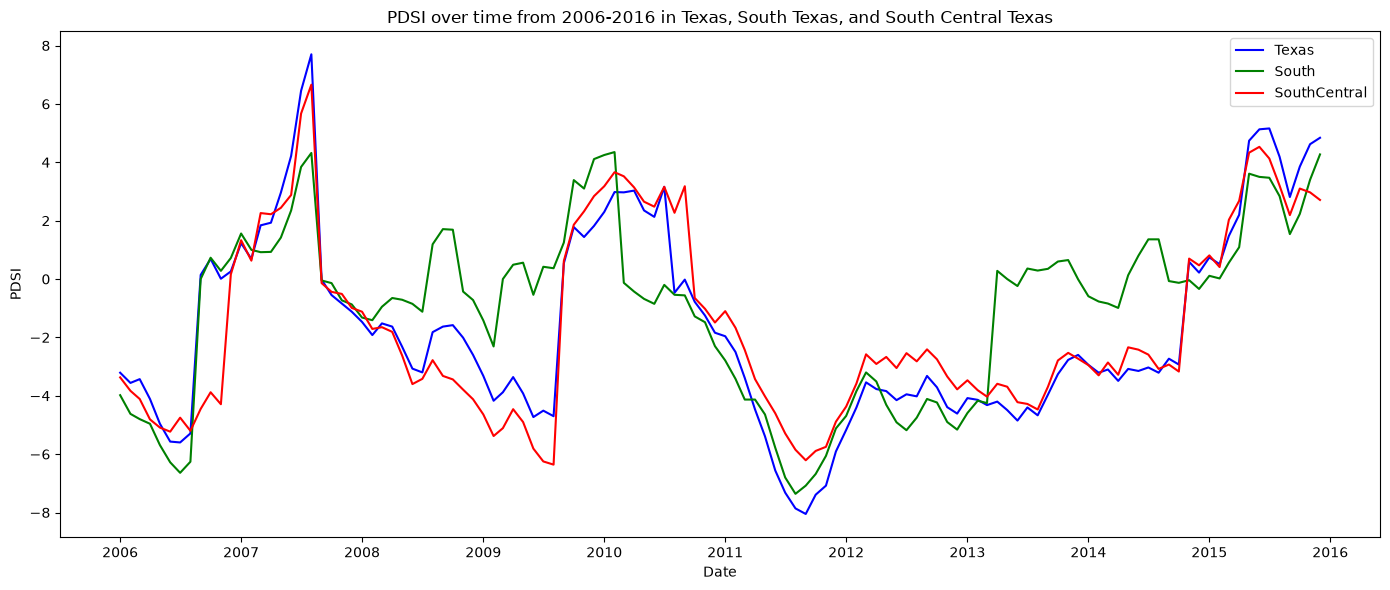

In [3]:
# make new 'Date' columns with more useable dates than 'YearMonth'
df_tx['Date'] = pd.to_datetime(df_tx['YearMonth'], format='%Y%m')
df_st['Date'] = pd.to_datetime(df_st['YearMonth'], format='%Y%m')
df_sc['Date'] = pd.to_datetime(df_sc['YearMonth'], format='%Y%m')

# canvas size from class demo
plt.figure(figsize=(14, 6))

# lineplots of data
sns.lineplot(x = 'Date', y='PDSI', data=df_tx, label='Texas', color='b')
sns.lineplot(x = 'Date', y='PDSI', data=df_st, label='South', color='g')
sns.lineplot(x = 'Date', y='PDSI', data=df_sc, label='SouthCentral', color='r')

# labels
plt.xlabel('Date')
plt.ylabel('PDSI')
plt.title('PDSI over time from 2006-2016 in Texas, South Texas, and South Central Texas')
plt.legend()

# showing plot
plt.tight_layout()
plt.show()

Part 3C (30 points):Descriptive statistics, correlation, and data analysis
1. Calculate descriptive statistics
For each dataset (South Region, Texas State, southcentral Division), calculate the standard deviation, mean, mode, and median for PDSI, temperature (TMP), and precipitation (PCP).

In [4]:
# making dicts for the stats
tx, st, sc = {'region' : 'Texas State'}, {'region' : 'South Region'}, {'region' : 'Southcentral Division'}

# stat calcs
for dataType in ('PDSI', 'TAVG', 'PCP') : # for each series of data needed to be worked on
    dt = 'average temperature' if dataType == 'TAVG' else 'precipitation' if dataType == 'PCP' else dataType # extra label var for easier print formatting later
    tx[dataType] = { # texas stats
        'dataType' : dt,
        'stdev' : float(df_tx[dataType].std()),
        'mean' : float(df_tx[dataType].mean()),
        'mode' : df_tx[dataType].mode()[0], # how the mode was formatted in class demo, but there may be multiple modes
        'median' : float(df_tx[dataType].median()) 
    }
    st[dataType] = { # south texas stats
            'dataType' : dt,
            'stdev' : float(df_st[dataType].std()),
            'mean' : float(df_st[dataType].mean()),
            'mode' : df_st[dataType].mode()[0], # how the mode was formatted in class demo, but there may be multiple modes
            'median' : float(df_st[dataType].median()) 
    }
    sc[dataType] = { # south central stats
        'dataType' : dt,
        'stdev' : float(df_sc[dataType].std()),
        'mean' : float(df_sc[dataType].mean()),
        'mode' : df_sc[dataType].mode()[0], # how the mode was formatted in class demo, but there may be multiple modes
        'median' : float(df_sc[dataType].median()) 
    }

# prints
for dataSet in (tx, st, sc) : # for each dataset
    print('--------------------'+dataSet['region']+'--------------------') # formatting (difficult to read wall of text otherwise)
    for dataType in ('PDSI', 'TAVG', 'PCP') :
        print(dataSet['region'], dataSet[dataType]['dataType'], 'standard deviation :', dataSet[dataType]['stdev'])
        print(dataSet['region'], dataSet[dataType]['dataType'], 'mean :', dataSet[dataType]['mean'])
        print(dataSet['region'], dataSet[dataType]['dataType'], 'median :', dataSet[dataType]['median'])
        print(dataSet['region'], dataSet[dataType]['dataType'], 'mode :', dataSet[dataType]['mode'])
        print() # formatting (difficult to read wall of text otherwise)

--------------------Texas State--------------------
Texas State PDSI standard deviation : 3.329852227102839
Texas State PDSI mean : -1.6803333333333335
Texas State PDSI median : -2.75
Texas State PDSI mode : -3.21

Texas State average temperature standard deviation : 13.430368093051133
Texas State average temperature mean : 65.93166666666667
Texas State average temperature median : 66.65
Texas State average temperature mode : 48.2

Texas State precipitation standard deviation : 1.4314957701844677
Texas State precipitation mean : 2.262833333333333
Texas State precipitation median : 2.1550000000000002
Texas State precipitation mode : 1.87

--------------------South Region--------------------
South Region PDSI standard deviation : 2.9399397419461692
South Region PDSI mean : -1.0161666666666667
South Region PDSI median : -0.43
South Region PDSI mode : 0.0

South Region average temperature standard deviation : 14.368052699490983
South Region average temperature mean : 63.15833333333333
Sout

2. Plot histograms:
plot three histograms of PDSI (one subplot for each dataset) with three rows and 1 column using the subplot() command. Add vertical lines representing each plot's mean, median, mode, and ± standard deviation. Follow the template in our class demo.

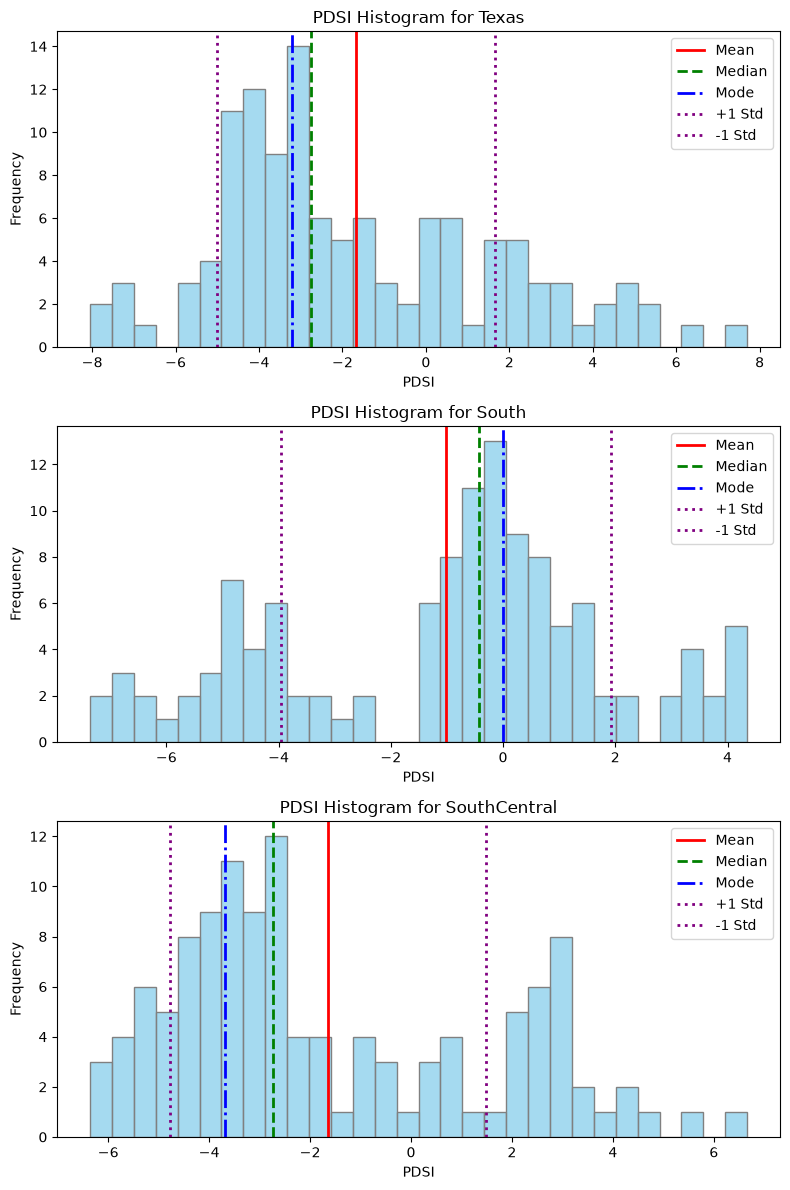

In [5]:
# canvas size from class demo
plt.figure(figsize=(8, 12))

# --- Texas ---
ax1 = plt.subplot(3, 1, 1) # from class demo
sns.histplot(df_tx['PDSI'], bins=30, color='skyblue', edgecolor='gray', ax=ax1) # making histogram

# setting vars from previous section
mean = tx['PDSI']['mean']
median = tx['PDSI']['median']
mode = tx['PDSI']['mode']
std = tx['PDSI']['stdev']

# from class demo w diff labels
ax1.axvline(mean, color='red', linestyle='-', linewidth=2, label='Mean')
ax1.axvline(median, color='green', linestyle='--', linewidth=2, label='Median')
ax1.axvline(mode, color='blue', linestyle='-.', linewidth=2, label='Mode')
ax1.axvline(mean+std, color='purple', linestyle=':', linewidth=2, label='+1 Std')
ax1.axvline(mean-std, color='purple', linestyle=':', linewidth=2, label='-1 Std')
ax1.set_title("PDSI Histogram for Texas")
ax1.set_xlabel("PDSI")
ax1.set_ylabel("Frequency")
ax1.legend()


# --- South ---
ax2 = plt.subplot(3, 1, 2) # from class demo
sns.histplot(df_st['PDSI'], bins=30, color='skyblue', edgecolor='gray', ax=ax2) # making histogram

# setting vars from previous section
mean = st['PDSI']['mean']
median = st['PDSI']['median']
mode = st['PDSI']['mode']
std = st['PDSI']['stdev']

# from class demo w diff labels
ax2.axvline(mean, color='red', linestyle='-', linewidth=2, label='Mean')
ax2.axvline(median, color='green', linestyle='--', linewidth=2, label='Median')
ax2.axvline(mode, color='blue', linestyle='-.', linewidth=2, label='Mode')
ax2.axvline(mean+std, color='purple', linestyle=':', linewidth=2, label='+1 Std')
ax2.axvline(mean-std, color='purple', linestyle=':', linewidth=2, label='-1 Std')
ax2.set_title("PDSI Histogram for South")
ax2.set_xlabel("PDSI")
ax2.set_ylabel("Frequency")
ax2.legend()

# --- SouthCentral ---
ax3 = plt.subplot(3, 1, 3) # from class demo
sns.histplot(df_sc['PDSI'], bins=30, color='skyblue', edgecolor='gray', ax=ax3) # making histogram

# setting vars from previous section
mean = sc['PDSI']['mean']
median = sc['PDSI']['median']
mode = sc['PDSI']['mode']
std = sc['PDSI']['stdev']

# from class demo w diff labels
ax3.axvline(mean, color='red', linestyle='-', linewidth=2, label='Mean')
ax3.axvline(median, color='green', linestyle='--', linewidth=2, label='Median')
ax3.axvline(mode, color='blue', linestyle='-.', linewidth=2, label='Mode')
ax3.axvline(mean+std, color='purple', linestyle=':', linewidth=2, label='+1 Std')
ax3.axvline(mean-std, color='purple', linestyle=':', linewidth=2, label='-1 Std')
ax3.set_title("PDSI Histogram for SouthCentral")
ax3.set_xlabel("PDSI")
ax3.set_ylabel("Frequency")
ax3.legend()

# showing plots
plt.tight_layout()
plt.show()


3. Describe the plot: Assess the drought severity during the selected period for each region based on the histogram plots.\
Type your answer here:\
\
Texas and South Central Texas have more months of lower indexes (more severe drought)\
Texas and South Central Texas have more months clustered around  a -4 PDSI with higher values bringing the average up, while South Texas has more months clustered around a 0 PDSI with loer values bringing the average down\
The distribution of Texas' PDSI values has one major peak, while the South Texas and South Central Texas have two peaks, indicating more dramatic fluctuations

4. Create scatter plot to compare the South region's PDSI with the Texas State PDSI, and compare the PDSI of South region vs that of south central region. So here both x and y will be PDSI. But we would have two clusters. Make sure to color them differently and provide legend for the color. Label the axes appropriately.


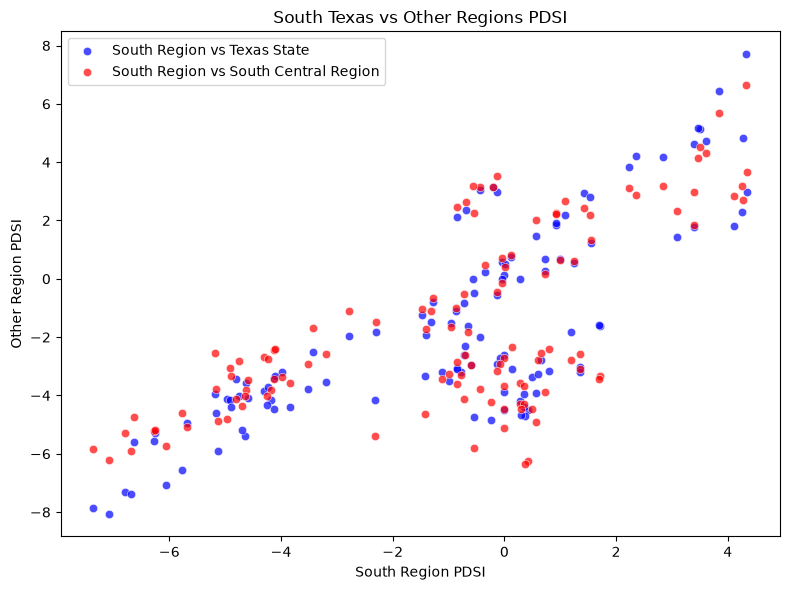

In [6]:
# canvas size from class demo
plt.figure(figsize=(8, 6))

# making scatterplots
sns.scatterplot(x=df_st['PDSI'], y=df_tx['PDSI'], color='b', alpha=0.7, label='South Region vs Texas State')
sns.scatterplot(x=df_st['PDSI'], y=df_sc['PDSI'], color='r', alpha=0.7, label='South Region vs South Central Region')
# sns.scatterplot(x=df_tx['PDSI'], y=df_sc['PDSI'], color='g', alpha=0.7, label='test') # to visualize the higher correlation coefficient

# legend and labels
plt.legend()
plt.xlabel("South Region PDSI")
plt.ylabel("Other Region PDSI")
plt.title("South Texas vs Other Regions PDSI")

# showing plot
plt.tight_layout()
plt.show()

6. Correlation coefficients: compute the correlation coefficients between PDSI values from different regions. (south vs texas, south vs south central, texas vs south central)


In [7]:
# calculating the correlation coefficients
stVtx = round(float(pearsonr(df_st['PDSI'], df_tx['PDSI'])[:][0]), 3)
stVsc = round(float(pearsonr(df_st['PDSI'], df_sc['PDSI'])[:][0]), 3)
txVsc = round(float(pearsonr(df_tx['PDSI'], df_sc['PDSI'])[:][0]), 3)

# printing the correlation coefficients
print('Correlation coefficient (South vs Texas PDSI) :', stVtx)
print('Correlation coefficient (South vs SouthCentral PDSI) :', stVsc)
print('Correlation coefficient (Texas vs SouthCentral PDSI) :', txVsc)

Correlation coefficient (South vs Texas PDSI) : 0.785
Correlation coefficient (South vs SouthCentral PDSI) : 0.667
Correlation coefficient (Texas vs SouthCentral PDSI) : 0.934


Explain the different correlation coeffcients in the context of the scatter plots you generated, focusing on the relationships between different regions.\
Type your answer here:\
\
Texas and South Central texas had the highest correllation coeffcient, which makes sense as they had the most similar line graphs and histograms\
Neither Texas nor South Central Texas were very correlated with South Texas, but out of the two Texas had the higher correlation coefficient with South Texas

7. Plot CDD vs HDD: Plot Cooling Degree Days (CDD) versus Heating Degree Days (HDD) for the Texas dataset and assess whether the relationship is linear. 

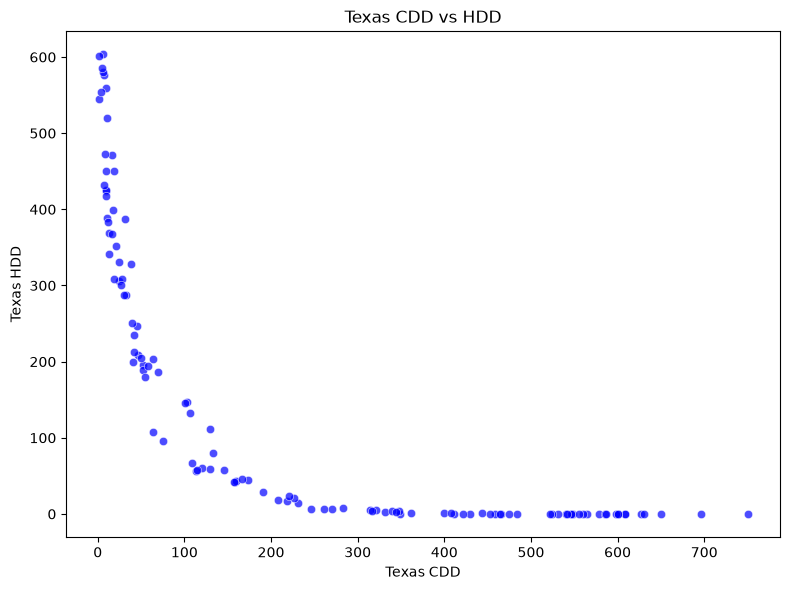

In [8]:
# canvas size from class demo
plt.figure(figsize=(8, 6))

# making scatterplot
sns.scatterplot(x=df_tx['CDD'], y=df_tx['HDD'], color='b', alpha=0.7)

# labels
plt.xlabel("Texas CDD")
plt.ylabel("Texas HDD")
plt.title("Texas CDD vs HDD")

# showing plot
plt.tight_layout()
plt.show()

In [9]:
# calculating and printing the correlation coefficient
txVtx = round(float(pearsonr(df_tx['CDD'], df_tx['HDD'])[:][0]), 3)
print('Correlation coefficient (Texas CDD vs Texas HDD):', txVtx)

Correlation coefficient (Texas CDD vs Texas HDD): -0.764


As seen in the graph and the low correlation coefficient, the relatinship between heating days and cooling days is not linear, and looks more similar to an inverse relationship

8. Correlation analysis:
Calculate the correlation coefficients between PDSI and PCP, PDSI and PHDI, and PDSI and ZNDX for Texas and the south central Region.

In [10]:
corrs = {'tx' : {'region' : 'Texas'}, 'sc' : {'region' : 'Central Region'}} # making dicts

# correlation coefficient calcs
for corr in ('PCP', 'PHDI', 'ZNDX') :
    corrs['tx'][corr] = round(float(pearsonr(df_tx['PDSI'], df_tx[corr])[:][0]), 3)
    corrs['sc'][corr] = round(float(pearsonr(df_sc['PDSI'], df_sc[corr])[:][0]), 3)

# correlation coefficient prints
for region in ('tx', 'sc') :
    for corr in ('PCP', 'PHDI', 'ZNDX') :
        print(corrs[region]['region'], 'PDSI v', corr, 'correlation coefficient :', corrs[region][corr])

Texas PDSI v PCP correlation coefficient : 0.47
Texas PDSI v PHDI correlation coefficient : 0.864
Texas PDSI v ZNDX correlation coefficient : 0.728
Central Region PDSI v PCP correlation coefficient : 0.497
Central Region PDSI v PHDI correlation coefficient : 0.869
Central Region PDSI v ZNDX correlation coefficient : 0.705


Describe the results: Highlight which variables are correlated and discuss their implications.

The most correlated values are the Palmer Drought Severity Index (PDSI) and the Palmer Hydrological Drought Index (PHDI). \
This makes sense as the PDHI is a measure of the hydrological impacts of the PDSI. It tends to respond more slowly to change than the PDSI, but is eventually changed to a similar extent. \
The Precipitation (PCP) and Palmer Z Index (ZNDX) values are both shorter-term measures and therefore change much more rapidly and unpredictibly than the PDSI.